# Combined Cycle Power Plant: ANN vs Classical Machine Learning (Regression)

**Goal:** predict the hourly net electrical energy output (**PE**, in MW) of a combined cycle power plant from four ambient sensor readings, and find out whether a neural network (ANN) actually beats classical regression algorithms.

| | |
|---|---|
| **Task** | Regression (single continuous target) |
| **Data** | 9,568 hourly readings, 4 numeric features |
| **Features** | `AT` ambient temperature (C), `V` exhaust vacuum (cm Hg), `AP` ambient pressure (mbar), `RH` relative humidity (%) |
| **Target** | `PE` net hourly electrical energy output (MW) |
| **Models compared** | Linear, Ridge, Lasso, Polynomial Regression, KNN, SVR, Decision Tree, Random Forest, Gradient Boosting, XGBoost, **ANN (PyTorch), two sizes** |
| **Metrics** | R2, RMSE (MW) and MAE (MW) |

## Evaluation protocol

1. Hold out **20 % of the data as a test set**. It is used once, at the end.
2. Compare all models with **5-fold cross-validation on the training set**.
3. Scaling lives **inside each pipeline**, so it is fit on training folds only (no data leakage).
4. The ANN standardises the target internally, uses an internal validation split for **early stopping**, and a learning-rate scheduler. It never sees the test data.
5. Two ANN sizes are compared: a tiny `4-6-6-1` network (a typical first attempt) and a wider `4-64-64-32-1` network, to show how model capacity affects the result.

## Contents

1. Setup
2. Load and explore the data
3. Preprocessing and train/test split
4. Models (including the PyTorch ANN)
5. Cross-validation and test results
6. Model comparison plots
7. Predicted vs actual and residuals
8. ANN deep dive: training curves
9. Feature importance
10. Save results
11. Conclusions

## 1. Setup

In [1]:
import os
import random
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from IPython.display import display
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LassoCV, LinearRegression, RidgeCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

SEED = 42
N_SPLITS = 5
TEST_SIZE = 0.20


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()

In [2]:
# Locate the dataset whether the notebook is run from the repo root or from notebooks/
DATA_FILE = "powerplant_data.csv"
candidates = [os.path.join("data", DATA_FILE), os.path.join("..", "data", DATA_FILE)]
DATA_PATH = next((p for p in candidates if os.path.exists(p)), None)
if DATA_PATH is None:
    raise FileNotFoundError(f"Put {DATA_FILE} inside the data/ folder of this repository.")

ROOT = os.path.dirname(os.path.dirname(DATA_PATH))
RESULTS_DIR = os.path.join(ROOT, "results")
FIG_DIR = os.path.join(RESULTS_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)


def save_fig(name):
    plt.savefig(os.path.join(FIG_DIR, name), dpi=150, bbox_inches="tight")

print("Data file :", DATA_PATH)
print("PyTorch   :", torch.__version__)

Data file : ../data/powerplant_data.csv
PyTorch   : 2.15.0+cu132


## 2. Load and explore the data

In [3]:
df = pd.read_csv(DATA_PATH)
print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns")
display(df.head())
display(df.describe().T.round(2))

Shape: 9568 rows x 5 columns


,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


,count,mean,std,min,25%,50%,75%,max
AT,9568.0,19.65,7.45,1.81,13.51,20.34,25.72,37.11
V,9568.0,54.31,12.71,25.36,41.74,52.08,66.54,81.56
AP,9568.0,1013.26,5.94,992.89,1009.10,1012.94,1017.26,1033.30
RH,9568.0,73.31,14.60,25.56,63.33,74.97,84.83,100.16
PE,9568.0,454.37,17.07,420.26,439.75,451.55,468.43,495.76


In [4]:
print("Missing values :", int(df.isnull().sum().sum()))
print("Duplicate rows :", int(df.duplicated().sum()))

Missing values : 0
Duplicate rows : 41


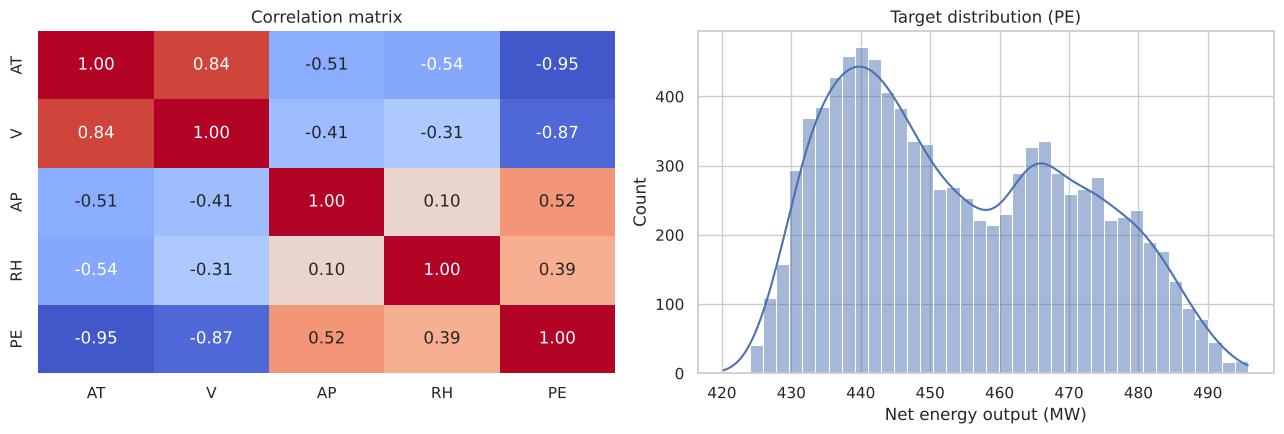

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[0], cbar=False)
axes[0].set_title("Correlation matrix")

sns.histplot(df["PE"], bins=40, kde=True, color="#4C72B0", ax=axes[1])
axes[1].set(title="Target distribution (PE)", xlabel="Net energy output (MW)")

plt.tight_layout()
save_fig("reg_correlation_and_target.png")
plt.show()

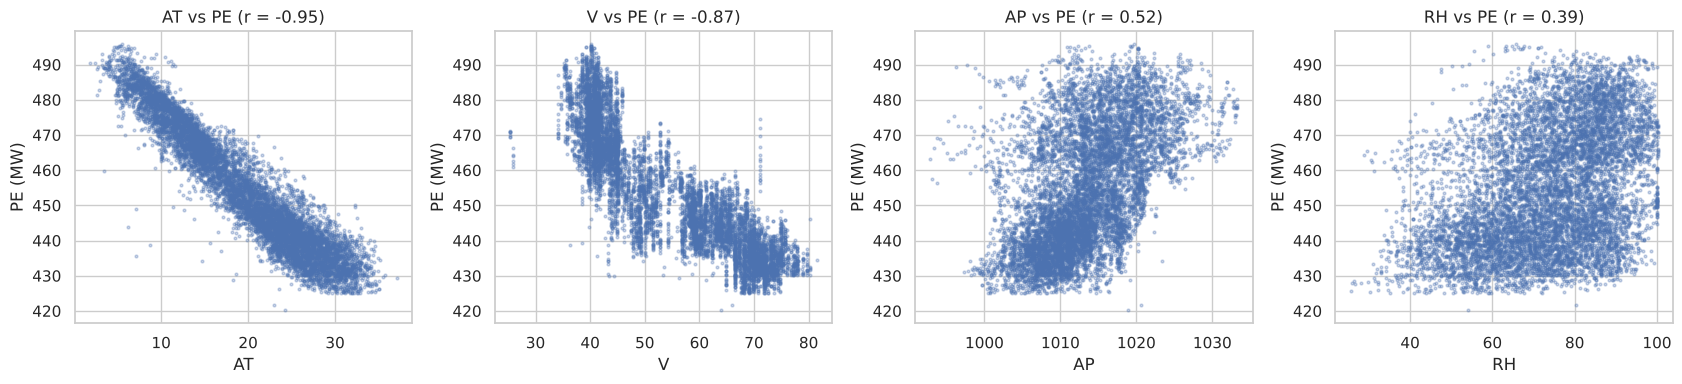

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, col in zip(axes, ["AT", "V", "AP", "RH"]):
    ax.scatter(df[col], df["PE"], s=4, alpha=0.3, color="#4C72B0")
    ax.set(title=f"{col} vs PE (r = {df[col].corr(df['PE']):.2f})", xlabel=col, ylabel="PE (MW)")
plt.tight_layout()
save_fig("reg_feature_vs_target.png")
plt.show()

**Observations**

- `AT` (temperature) and `V` (exhaust vacuum) have a strong negative correlation with output. `AT` is the single most informative feature, and its relationship with `PE` is close to linear.
- `AP` and `RH` have weaker, noisier relationships.
- `AT` and `V` are strongly correlated with each other, so linear models see partly redundant information.
- Because the main relationship is nearly linear, simple models should already do well. The question is how much extra signal the non-linear models can capture.

## 3. Preprocessing and train/test split

In [7]:
X = df.drop(columns="PE")
y = df["PE"]
feature_names = list(X.columns)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=SEED)
print(f"Train: {X_train.shape[0]} samples | Test: {X_test.shape[0]} samples")
print(f"Target range (train): {y_train.min():.1f} to {y_train.max():.1f} MW, std = {y_train.std():.2f} MW")
print(f"Baseline RMSE if we always predict the mean: {np.sqrt(((y_test - y_train.mean()) ** 2).mean()):.2f} MW")

Train: 7654 samples | Test: 1914 samples
Target range (train): 420.3 to 495.8 MW, std = 17.10 MW
Baseline RMSE if we always predict the mean: 16.92 MW


## 4. Models

Every model is wrapped in a scikit-learn `Pipeline`. Models that depend on feature scale get a `StandardScaler` as their first step. Tree-based models do not need scaling.

The ANN is written in **PyTorch** and wrapped in a scikit-learn-compatible class (`TorchANNRegressor`) so it goes through exactly the same cross-validation code as every other model.

**ANN design details**
- The target is standardised inside the model (the raw target is around 420 to 500, which makes early training slow) and predictions are converted back to MW.
- Adam optimizer, MSE loss, early stopping on validation loss, and `ReduceLROnPlateau` to lower the learning rate when progress stalls.

In [8]:
class MLP(nn.Module):
    """Fully connected network: [Linear -> ReLU -> Dropout] x N -> Linear(1)."""

    def __init__(self, in_dim, hidden, dropout):
        super().__init__()
        layers, prev = [], in_dim
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU(), nn.Dropout(dropout)]
            prev = h
        layers.append(nn.Linear(prev, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(1)


class TorchANNRegressor(RegressorMixin, BaseEstimator):
    """PyTorch ANN with a scikit-learn API. Expects scaled inputs; standardises the target internally."""

    def __init__(self, hidden=(64, 64, 32), dropout=0.0, lr=1e-3, weight_decay=0.0,
                 batch_size=64, max_epochs=200, patience=20, val_size=0.15, random_state=SEED):
        self.hidden = hidden
        self.dropout = dropout
        self.lr = lr
        self.weight_decay = weight_decay
        self.batch_size = batch_size
        self.max_epochs = max_epochs
        self.patience = patience
        self.val_size = val_size
        self.random_state = random_state

    def fit(self, X, y):
        set_seed(self.random_state)
        X = np.asarray(X, dtype=np.float32)
        y = np.asarray(y, dtype=np.float32)

        # Internal validation split used only for early stopping
        X_tr, X_val, y_tr, y_val = train_test_split(
            X, y, test_size=self.val_size, random_state=self.random_state
        )
        self.y_mean_, self.y_std_ = float(y_tr.mean()), float(y_tr.std())
        X_tr, X_val = torch.from_numpy(X_tr), torch.from_numpy(X_val)
        y_tr = torch.from_numpy((y_tr - self.y_mean_) / self.y_std_)
        y_val = torch.from_numpy((y_val - self.y_mean_) / self.y_std_)

        self.model_ = MLP(X.shape[1], self.hidden, self.dropout)
        criterion = nn.MSELoss()
        optimizer = torch.optim.Adam(self.model_.parameters(), lr=self.lr, weight_decay=self.weight_decay)
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=5)

        # history_: losses are MSE on the standardised target; val_rmse is converted back to MW
        self.history_ = {"train_loss": [], "val_loss": [], "val_rmse": []}
        best_val, best_state, wait, n = np.inf, None, 0, len(X_tr)
        self.best_epoch_ = 0

        for epoch in range(self.max_epochs):
            # ---- training pass ----
            self.model_.train()
            order = torch.randperm(n)
            running = 0.0
            for i in range(0, n, self.batch_size):
                idx = order[i:i + self.batch_size]
                optimizer.zero_grad()
                loss = criterion(self.model_(X_tr[idx]), y_tr[idx])
                loss.backward()
                optimizer.step()
                running += loss.item() * len(idx)

            # ---- validation pass ----
            self.model_.eval()
            with torch.no_grad():
                val_loss = criterion(self.model_(X_val), y_val).item()

            self.history_["train_loss"].append(running / n)
            self.history_["val_loss"].append(val_loss)
            self.history_["val_rmse"].append(float(np.sqrt(val_loss)) * self.y_std_)
            scheduler.step(val_loss)

            # ---- early stopping ----
            if val_loss < best_val - 1e-5:
                best_val, wait, self.best_epoch_ = val_loss, 0, epoch + 1
                best_state = {k: v.clone() for k, v in self.model_.state_dict().items()}
            else:
                wait += 1
                if wait >= self.patience:
                    break

        self.model_.load_state_dict(best_state)
        self.model_.eval()
        return self

    def predict(self, X):
        with torch.no_grad():
            out = self.model_(torch.from_numpy(np.asarray(X, dtype=np.float32))).numpy()
        return out * self.y_std_ + self.y_mean_

In [9]:
def scaled(estimator):
    """StandardScaler + estimator, fit on training data only."""
    return Pipeline([("scaler", StandardScaler()), ("model", estimator)])


models = {
    "Linear Regression": scaled(LinearRegression()),
    "Ridge (CV alpha)": scaled(RidgeCV(alphas=np.logspace(-3, 3, 13))),
    "Lasso (CV alpha)": scaled(LassoCV(cv=5, random_state=SEED)),
    "Polynomial Regression (deg 3)": scaled(Pipeline([
        ("poly", PolynomialFeatures(degree=3, include_bias=False)),
        ("lin", LinearRegression()),
    ])),
    "KNN (k=5)": scaled(KNeighborsRegressor(n_neighbors=5)),
    "SVR (RBF)": TransformedTargetRegressor(
        regressor=scaled(SVR(C=10)), transformer=StandardScaler()
    ),
    "Decision Tree": DecisionTreeRegressor(max_depth=8, random_state=SEED),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=SEED),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=300, max_depth=3, random_state=SEED),
    "XGBoost": XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=5, random_state=SEED, verbosity=0),
    "ANN 6-6 (small)": scaled(TorchANNRegressor(hidden=(6, 6))),
    "ANN 64-64-32 (wide)": scaled(TorchANNRegressor(hidden=(64, 64, 32))),
}
print(f"{len(models)} models ready:", ", ".join(models))

12 models ready: Linear Regression, Ridge (CV alpha), Lasso (CV alpha), Polynomial Regression (deg 3), KNN (k=5), SVR (RBF), Decision Tree, Random Forest, Gradient Boosting, XGBoost, ANN 6-6 (small), ANN 64-64-32 (wide)


## 5. Cross-validation and test results

For each model:
- **5-fold CV on the training set** gives the mean and standard deviation of R2, RMSE and MAE. This is the number to use for ranking.
- The model is then **refit on the full training set** and scored once on the held-out **test set**.

*This cell trains 12 models with 6 fits each, so it takes a few minutes.*

In [10]:
kf = KFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
scoring = {"r2": "r2", "rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error"}

rows, fitted, test_pred = [], {}, {}
for name, model in models.items():
    cv = cross_validate(model, X_train, y_train, cv=kf, scoring=scoring)

    t0 = time.time()
    model.fit(X_train, y_train)
    fit_time = time.time() - t0

    pred = model.predict(X_test)
    fitted[name], test_pred[name] = model, pred
    rows.append({
        "Model": name,
        "CV R2": cv["test_r2"].mean(),
        "CV R2 Std": cv["test_r2"].std(),
        "CV RMSE": -cv["test_rmse"].mean(),
        "CV MAE": -cv["test_mae"].mean(),
        "Test R2": r2_score(y_test, pred),
        "Test RMSE": float(np.sqrt(mean_squared_error(y_test, pred))),
        "Test MAE": mean_absolute_error(y_test, pred),
        "Fit Time (s)": fit_time,
    })
    print(f"{name:30s} CV R2 = {rows[-1]['CV R2']:.4f} | CV RMSE = {rows[-1]['CV RMSE']:.3f} MW | test R2 = {rows[-1]['Test R2']:.4f}")

results = pd.DataFrame(rows).sort_values("CV RMSE").reset_index(drop=True)
results.index += 1

Linear Regression              CV R2 = 0.9278 | CV RMSE = 4.593 MW | test R2 = 0.9315
Ridge (CV alpha)               CV R2 = 0.9278 | CV RMSE = 4.593 MW | test R2 = 0.9315


Lasso (CV alpha)               CV R2 = 0.9278 | CV RMSE = 4.593 MW | test R2 = 0.9315
Polynomial Regression (deg 3)  CV R2 = 0.9397 | CV RMSE = 4.198 MW | test R2 = 0.9430
KNN (k=5)                      CV R2 = 0.9461 | CV RMSE = 3.966 MW | test R2 = 0.9522


SVR (RBF)                      CV R2 = 0.9452 | CV RMSE = 4.001 MW | test R2 = 0.9470
Decision Tree                  CV R2 = 0.9406 | CV RMSE = 4.165 MW | test R2 = 0.9419


Random Forest                  CV R2 = 0.9591 | CV RMSE = 3.454 MW | test R2 = 0.9648


Gradient Boosting              CV R2 = 0.9555 | CV RMSE = 3.606 MW | test R2 = 0.9593


XGBoost                        CV R2 = 0.9619 | CV RMSE = 3.336 MW | test R2 = 0.9656


ANN 6-6 (small)                CV R2 = 0.9393 | CV RMSE = 4.213 MW | test R2 = 0.9418


ANN 64-64-32 (wide)            CV R2 = 0.9471 | CV RMSE = 3.929 MW | test R2 = 0.9501


In [11]:
display(results.round(4))

,Model,CV R2,CV R2 Std,CV RMSE,CV MAE,Test R2,Test RMSE,Test MAE,Fit Time (s)
1,XGBoost,0.9619,0.0011,3.3361,2.4082,0.9656,3.1395,2.2736,0.3323
2,Random Forest,0.9591,0.0015,3.4543,2.4659,0.9648,3.1749,2.2562,6.3821
3,Gradient Boosting,0.9555,0.0014,3.6061,2.6871,0.9593,3.4128,2.5983,2.4843
4,ANN 64-64-32 (wide),0.9471,0.0017,3.9293,2.9602,0.9501,3.7774,2.8261,10.1972
5,KNN (k=5),0.9461,0.0021,3.9662,2.8909,0.9522,3.7002,2.7067,0.0068
6,SVR (RBF),0.9452,0.0019,4.0006,2.9843,0.9470,3.8951,2.9292,3.1702
7,Decision Tree,0.9406,0.0030,4.1651,3.0691,0.9419,4.0767,2.9966,0.0264
8,Polynomial Regression (deg 3),0.9397,0.0025,4.1978,3.2602,0.9430,4.0399,3.1742,0.0109
9,ANN 6-6 (small),0.9393,0.0019,4.2126,3.2783,0.9418,4.0824,3.1909,5.7816
10,Linear Regression,0.9278,0.0015,4.5929,3.6500,0.9315,4.4281,3.5434,0.0030


## 6. Model comparison plots

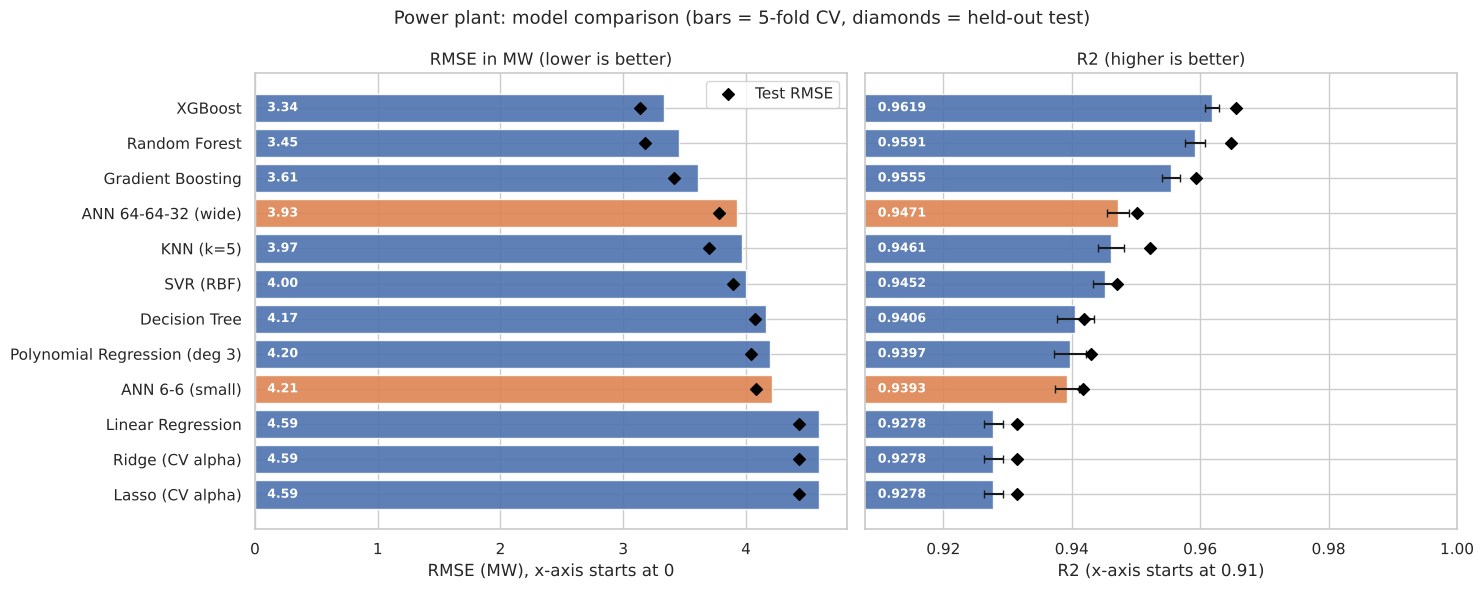

In [12]:
order = results.sort_values("CV RMSE", ascending=False)
colors = ["#DD8452" if m.startswith("ANN") else "#4C72B0" for m in order["Model"]]

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

axes[0].barh(order["Model"], order["CV RMSE"], color=colors, alpha=0.9)
axes[0].scatter(order["Test RMSE"], order["Model"], marker="D", color="black", zorder=3, label="Test RMSE")
for y_pos, v in enumerate(order["CV RMSE"]):
    axes[0].text(0.1, y_pos, f"{v:.2f}", va="center", ha="left", color="white", fontsize=9, fontweight="bold")
axes[0].set(title="RMSE in MW (lower is better)", xlabel="RMSE (MW), x-axis starts at 0")
axes[0].legend(loc="upper right")

axes[1].barh(order["Model"], order["CV R2"], xerr=order["CV R2 Std"], color=colors, capsize=3, alpha=0.9)
axes[1].scatter(order["Test R2"], order["Model"], marker="D", color="black", zorder=3)
r2_min = max(0.0, order["CV R2"].min() - 0.02)
axes[1].set_xlim(r2_min, 1.0)
for y_pos, v in enumerate(order["CV R2"]):
    axes[1].text(r2_min + 0.002, y_pos, f"{v:.4f}", va="center", ha="left", color="white", fontsize=9, fontweight="bold")
axes[1].set(title="R2 (higher is better)", xlabel=f"R2 (x-axis starts at {r2_min:.2f})")

fig.suptitle("Power plant: model comparison (bars = 5-fold CV, diamonds = held-out test)", fontsize=13)
plt.tight_layout()
save_fig("reg_model_comparison.png")
plt.show()

**How to read this:** RMSE and MAE are in **megawatts**, so they are directly interpretable (an RMSE of 3.3 means predictions are typically off by about 3.3 MW on a plant that produces 420 to 496 MW). The R2 panel zooms in because all good models score above 0.9, so read it together with the RMSE panel, which starts at zero.

## 7. Predicted vs actual and residuals

Top row: predicted vs actual values (points on the dashed diagonal are perfect predictions). Bottom row: residuals (actual minus predicted); they should be centred on zero with no visible pattern. Shown for the best model by cross-validation and for the wide ANN.

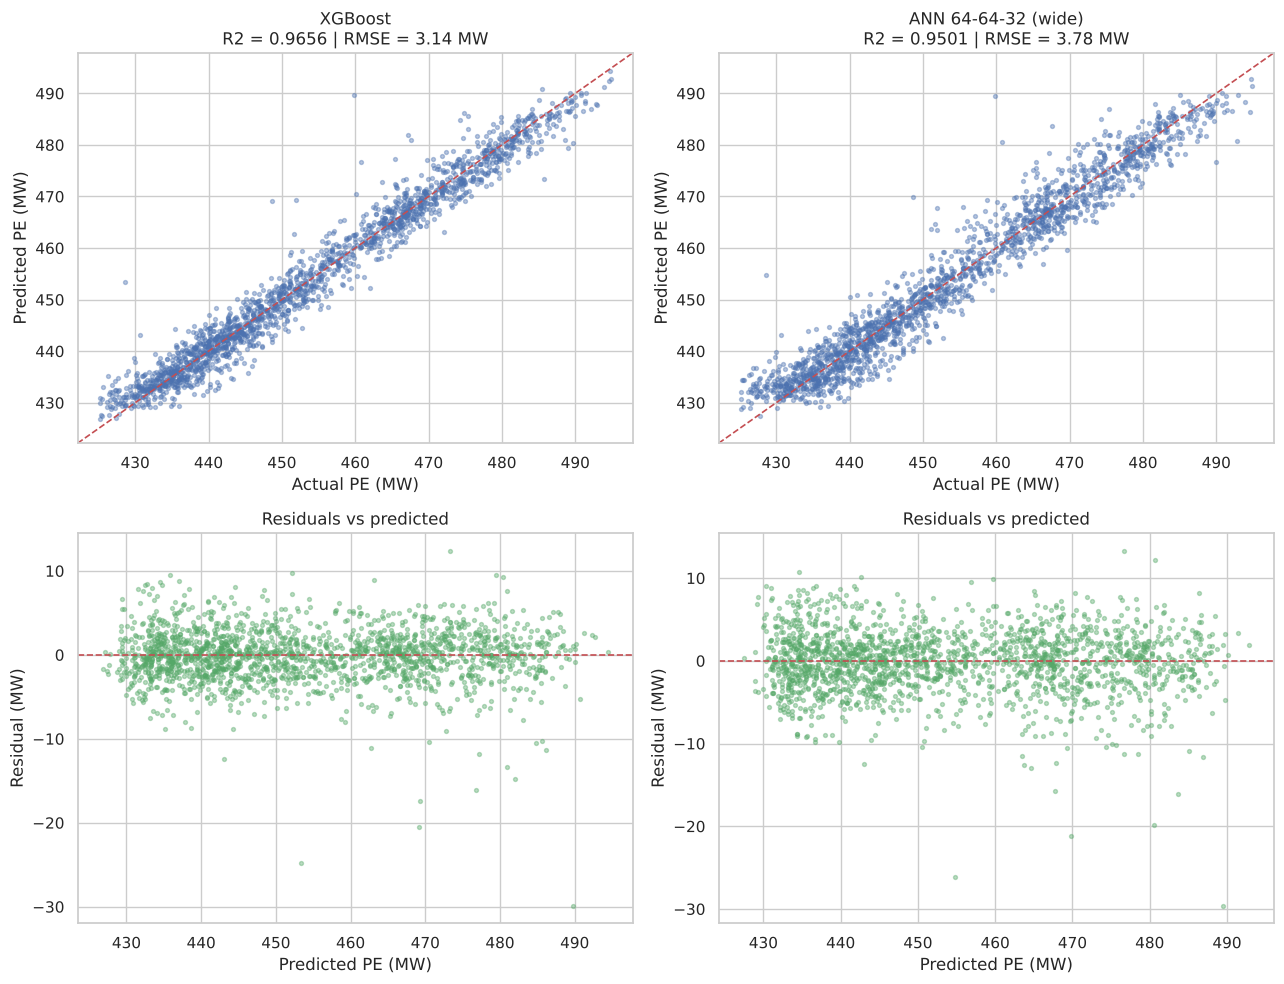

In [13]:
ann_name = "ANN 64-64-32 (wide)"
best_name = results.loc[1, "Model"]
show = [best_name] if best_name == ann_name else [best_name, ann_name]
if len(show) == 1:  # ANN is the best model: show the runner-up next to it
    show.append(results.loc[2, "Model"])

lo, hi = float(y_test.min()) - 3, float(y_test.max()) + 3
fig, axes = plt.subplots(2, len(show), figsize=(6.5 * len(show), 10))
for col, name in enumerate(show):
    pred = test_pred[name]
    resid = y_test.values - pred
    rmse = np.sqrt(mean_squared_error(y_test, pred))

    ax = axes[0, col]
    ax.scatter(y_test, pred, s=8, alpha=0.4, color="#4C72B0")
    ax.plot([lo, hi], [lo, hi], "r--", lw=1.2)
    ax.set(title=f"{name}\nR2 = {r2_score(y_test, pred):.4f} | RMSE = {rmse:.2f} MW",
           xlabel="Actual PE (MW)", ylabel="Predicted PE (MW)", xlim=(lo, hi), ylim=(lo, hi))

    ax = axes[1, col]
    ax.scatter(pred, resid, s=8, alpha=0.4, color="#55A868")
    ax.axhline(0, color="r", linestyle="--", lw=1.2)
    ax.set(title="Residuals vs predicted", xlabel="Predicted PE (MW)", ylabel="Residual (MW)")
plt.tight_layout()
save_fig("reg_predicted_vs_actual.png")
plt.show()

## 8. ANN deep dive: training curves

Curves from the final fit of the wide ANN (left: loss on the standardised target, right: validation RMSE converted back to MW). The model keeps the weights from the epoch with the lowest validation loss.

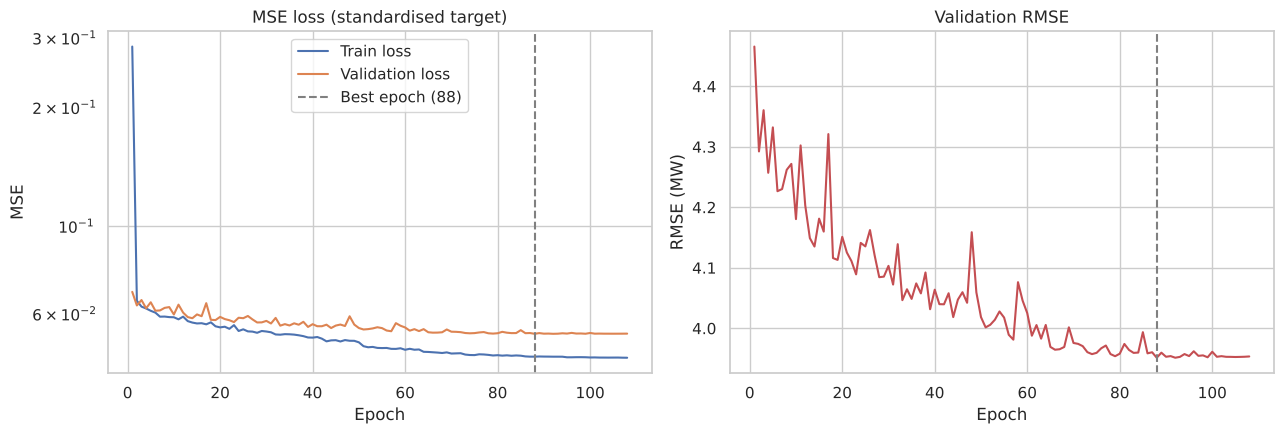

Training stopped after 108 epochs; best epoch = 88.


In [14]:
ann = fitted[ann_name].named_steps["model"]
hist = ann.history_
epochs = range(1, len(hist["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(epochs, hist["train_loss"], label="Train loss")
axes[0].plot(epochs, hist["val_loss"], label="Validation loss")
axes[0].axvline(ann.best_epoch_, color="gray", linestyle="--", label=f"Best epoch ({ann.best_epoch_})")
axes[0].set(title="MSE loss (standardised target)", xlabel="Epoch", ylabel="MSE")
axes[0].set_yscale("log")
axes[0].legend()

axes[1].plot(epochs, hist["val_rmse"], color="#C44E52")
axes[1].axvline(ann.best_epoch_, color="gray", linestyle="--")
axes[1].set(title="Validation RMSE", xlabel="Epoch", ylabel="RMSE (MW)")
plt.tight_layout()
save_fig("reg_ann_training_curves.png")
plt.show()
print(f"Training stopped after {len(epochs)} epochs; best epoch = {ann.best_epoch_}.")

## 9. Feature importance

Random Forest impurity importance and permutation importance on the test set (how much the error grows when one feature is shuffled). Permutation importance is the more reliable of the two.

,Impurity importance,"Permutation importance (RMSE increase, MW)"
AT,0.8931,17.4270
V,0.0694,3.2798
AP,0.0195,0.8783
RH,0.0180,0.8622


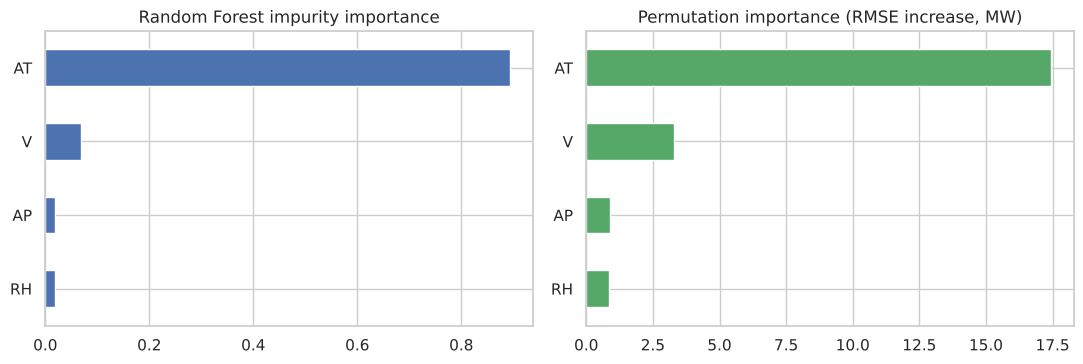

In [15]:
from sklearn.inspection import permutation_importance

rf = fitted["Random Forest"]
perm = permutation_importance(rf, X_test, y_test, n_repeats=10, random_state=SEED, scoring="neg_root_mean_squared_error")

imp = pd.DataFrame({
    "Impurity importance": rf.feature_importances_,
    "Permutation importance (RMSE increase, MW)": perm.importances_mean,
}, index=feature_names).sort_values("Permutation importance (RMSE increase, MW)", ascending=False)
display(imp.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
imp["Impurity importance"].sort_values().plot.barh(ax=axes[0], color="#4C72B0")
axes[0].set_title("Random Forest impurity importance")
imp["Permutation importance (RMSE increase, MW)"].sort_values().plot.barh(ax=axes[1], color="#55A868")
axes[1].set_title("Permutation importance (RMSE increase, MW)")
plt.tight_layout()
save_fig("reg_feature_importance.png")
plt.show()

## 10. Save results

In [16]:
results.round(4).to_csv(os.path.join(RESULTS_DIR, "regression_results.csv"), index_label="Rank")
print("Saved:", os.path.join(RESULTS_DIR, "regression_results.csv"))
print("Figures:", sorted(os.listdir(FIG_DIR)))

Saved: ../results/regression_results.csv
Figures: ['cls_ann_training_curves.png', 'cls_class_distribution.png', 'cls_confusion_matrices.png', 'cls_model_comparison.png', 'reg_ann_training_curves.png', 'reg_correlation_and_target.png', 'reg_feature_importance.png', 'reg_feature_vs_target.png', 'reg_model_comparison.png', 'reg_predicted_vs_actual.png']


## 11. Conclusions

**1. Tree ensembles beat the neural network on this dataset.**
Cross-validated RMSE: XGBoost 3.34 MW, Random Forest 3.45 MW, Gradient Boosting 3.61 MW, wide ANN 3.93 MW, Linear Regression 4.59 MW (R2 0.962, 0.959, 0.956, 0.947 and 0.928). XGBoost's error is about 15 % lower than the wide ANN's and about 27 % lower than Linear Regression's. The fold-to-fold standard deviation of R2 is only about 0.001 to 0.002, so the gap between XGBoost and the ANN (0.015 R2) is far outside the noise. The held-out test set tells the same story (XGBoost 3.14 MW vs ANN 3.78 MW).

**2. The ANN is clearly better than linear models, but not the best.**
The wide ANN (`4-64-64-32-1`) cuts RMSE by about 0.66 MW compared with Linear Regression. It is on par with KNN and SVR, which are also smooth non-linear models. On small tabular data with only 4 features, boosted trees are usually hard to beat, and that is what happened here.

**3. Model capacity matters for the ANN.**
The tiny `4-6-6-1` network (R2 0.939, RMSE 4.21 MW) performs like a degree-3 polynomial or a single Decision Tree. Widening it to `64-64-32` improved RMSE by about 0.3 MW. Standardising the target, early stopping and a learning-rate scheduler make training stable, but they cannot add capacity the network does not have.

**4. Regularisation does nothing here.**
Ridge and Lasso give exactly the same result as plain Linear Regression (R2 0.9278). With 4 features and about 7,600 training rows there is no overfitting to correct.

**5. Ambient temperature drives almost everything.**
Permutation importance (increase in RMSE when a feature is shuffled): `AT` 17.4 MW, `V` 3.3 MW, `AP` 0.9 MW, `RH` 0.9 MW. `AT` alone accounts for about 89 % of the Random Forest's impurity importance. That also explains why linear models already reach R2 0.93.

**6. Residuals look healthy.**
Residuals are centred on zero with no obvious pattern, for both XGBoost and the ANN. A handful of large negative residuals (down to about -30 MW) appear in both models, which suggests unusual operating conditions that these four sensors cannot explain.

### Practical takeaway
For this problem, **XGBoost is the best choice**: the lowest error, and it trains in about 0.3 seconds compared with about 11 seconds for the ANN. The ANN is still useful as a learning exercise and as a baseline, but it is not the right production model for 4 tabular features.

### Limitations

- No model was hyperparameter-tuned beyond sensible defaults. Tuned XGBoost, SVR or ANN models could shift the ranking slightly.
- The dataset contains 41 duplicate rows, which were kept. A few may appear in both the training and test sets, with negligible effect at this scale.
- The ANN trains on 85 % of each training fold (15 % is used for early stopping).

### Next steps

- Tune XGBoost and the ANN with Optuna or randomised search, using nested cross-validation.
- Try stacking or averaging XGBoost and the ANN, since their errors are not identical.
- Serve the best model behind a Streamlit or FastAPI app.